In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
#from torchinfo import summary

## ImageNet

### checking size

In [186]:
import requests

url = "https://data.vision.ee.ethz.ch/cvl/DIV2K/DIV2K_train_LR_bicubic_X4.zip"#'https://data.vision.ee.ethz.ch/cvl/DIV2K/DIV2K_train_HR.zip'
response = requests.head(url)

# Content-Length is in bytes
size_in_gb = int(response.headers['Content-Length']) / (1024**3)
print(f"Estimated size: {size_in_gb:.2f} GB")

Estimated size: 0.23 GB


### downloading

In [19]:
import os
import urllib.request
from zipfile import ZipFile

def download_div2k_x4(destination='./DIV2K'):
    os.makedirs(destination, exist_ok=True)

    urls = {
        "train_X4": "https://data.vision.ee.ethz.ch/cvl/DIV2K/DIV2K_train_LR_bicubic_X4.zip",
        "valid_X4": "https://data.vision.ee.ethz.ch/cvl/DIV2K/DIV2K_valid_LR_bicubic_X4.zip"
    }

    for name, url in urls.items():
        zip_path = os.path.join(destination, f"{name}.zip")
        print(f"Downloading {name}...")
        urllib.request.urlretrieve(url, zip_path)
        print(f"Extracting {name}...")
        with ZipFile(zip_path, 'r') as zip_ref:
            zip_ref.extractall(destination)
        os.remove(zip_path)
        print(f"Done with {name}.")

# Run it
download_div2k_x4()

Extracting train_X4...
Done with train_X4.
Extracting valid_X4...
Done with valid_X4.


### loading images

In [2]:
import os
from PIL import Image
import torch
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms

class DIV2KDataset(Dataset):
    def __init__(self, root_dir, transform=None, grayscale=True):
        """
        Args:
            root_dir (string): Path to the dataset folder (e.g., 'DIV2K_train_HR')
            transform (callable, optional): Optional transform to be applied on a sample.
            grayscale (bool): If True, load images as grayscale (1 channel), else as RGB (3 channels).
        """
        self.root_dir = root_dir
        self.transform = transform
        self.grayscale = grayscale
        self.image_filenames = sorted([
            fname for fname in os.listdir(root_dir) 
            if fname.endswith('.png') or fname.endswith('.jpg')
        ])

    def __len__(self):
        return len(self.image_filenames)

    def __getitem__(self, idx):
        img_path = os.path.join(self.root_dir, self.image_filenames[idx])

        # conversion mode:
        if self.grayscale:
            image = Image.open(img_path).convert('L')  # 'L' mode = grayscale
        else:
            image = Image.open(img_path).convert('RGB')  # RGB

        if self.transform:
            image = self.transform(image)
        return image

In [3]:
#  transforms definition
transform = transforms.Compose([
    transforms.Resize((128, 128)),  # optional resize
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

grayscale = True


#### local

In [4]:
train_path = './DIV2K/DIV2K_train_LR_bicubic/X4'
valid_path = './DIV2K/DIV2K_valid_LR_bicubic/X4'

# Loading datasets
trainset = DIV2KDataset(root_dir=train_path, transform=transform, grayscale=grayscale)
valset   = DIV2KDataset(root_dir=valid_path, transform=transform, grayscale=grayscale)

#### google colab

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
# Base path to your Drive folder
base_path = '/content/drive/MyDrive/Image Inpainting/DIV2K'

# Now set paths
train_path = base_path + '/DIV2K_train_LR_bicubic/X4'
valid_path = base_path + '/DIV2K_valid_LR_bicubic/X4'

# Loading datasets
trainset = DIV2KDataset(root_dir=train_path, transform=transform, grayscale=grayscale)
valset   = DIV2KDataset(root_dir=valid_path, transform=transform, grayscale=grayscale)

### batch initialization

In [5]:
# Creating DataLoaders
batch_size = 4

trainloader = DataLoader(trainset, batch_size=batch_size, shuffle=True)
valloader   = DataLoader(valset, batch_size=batch_size, shuffle=False)

## masks

In [6]:
def generate_random_mask(image_size, max_num_patches=100, max_patch_size=10):
    """
    Create a random mask with several missing square patches.
    - image_size: (C, H, W)
    - max_num_patches: maximum number of patches to mask
    - max_patch_size: maximum size of each square patch
    """
    C, H, W = image_size
    mask = torch.ones((C, H, W), dtype=torch.float32)

    num_patches = np.random.randint(1, max_num_patches + 1)
    for _ in range(num_patches):
        h = np.random.randint(5, max_patch_size)
        w = np.random.randint(5, max_patch_size)
        top = np.random.randint(0, H - h)
        left = np.random.randint(0, W - w)
        mask[:, top:top + h, left:left + w] = 0
    return mask

In [7]:
def generate_center_mask(image_size, box_size_ratio=0.25):
    """
    Create a center mask with a square missing patch.
    - image_size: (C, H, W)
    - box_size_ratio: size of square as a fraction of image height/width
    """
    C, H, W = image_size
    mask = torch.ones((C, H, W), dtype=torch.float32)

    box_size = int(min(H, W) * box_size_ratio)
    top = (H - box_size) // 2
    left = (W - box_size) // 2
    mask[:, top:top + box_size, left:left + box_size] = 0
    return mask

## sanity check

In [ ]:
def imshow(img,save_path=None):
    img = img / 2 + 0.5     # unnormalize to show images correctly
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    if save_path is not None:
        plt.savefig(save_path, dpi=600)
    plt.show()

torch.Size([4, 1, 128, 128])


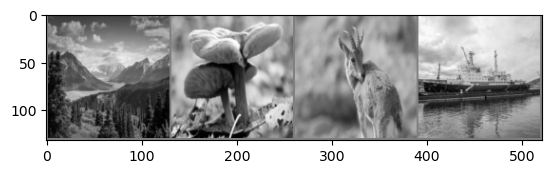

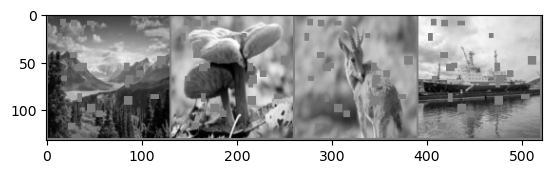

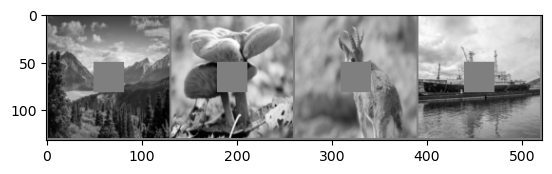

In [9]:
# Print some samples of dataset as a sanity check

# Get some random training images
dataiter = iter(trainloader)
example_images = next(dataiter)

print(example_images.shape)

# Show images
imshow(torchvision.utils.make_grid(example_images))

# Apply random mask
random_mask = generate_random_mask(example_images[0].shape)
masked_images_random = example_images * random_mask

# Show masked images (random mask)
imshow(torchvision.utils.make_grid(masked_images_random))

# Apply center mask
center_mask = generate_center_mask(example_images[0].shape)
masked_images_center = example_images * center_mask

# Show masked images (center mask)
imshow(torchvision.utils.make_grid(masked_images_center))

## architecture

### partial convolution

source for [class PartialConv2d(nn.Conv2d):
](https://github.com/NVIDIA/partialconv/blob/master/models/partialconv2d.py)
also used in [Implementing Inpainting GANs](https://www.kaggle.com/code/aschamp/implementing-inpainting-gans#3.-Partial-Convolutions)

In [10]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class PartialConv2d(nn.Conv2d):
    def __init__(self, *args, **kwargs):
        super(PartialConv2d, self).__init__(*args, **kwargs)

        self.mask_update_kernel = torch.ones(self.out_channels, self.in_channels, 
                                             self.kernel_size[0], self.kernel_size[1]).to(device).type(torch.float32)
        self.mask_update_area = self.in_channels * self.kernel_size[0] * self.kernel_size[1]
        
    
    def forward(self, input, mask = None):
        h, w = input.shape[2:]
        with torch.no_grad():
            if mask is None:
                mask = torch.ones(input.shape[0], input.shape[1], h, w).to(device).type(torch.float32)

            next_mask = F.conv2d(
                mask, 
                self.mask_update_kernel,
                stride = self.stride,
                padding = self.padding,
                dilation = self.dilation
            )

            # partial conv has (kernel_area / sum(mask)) * convolution if sum(mask) > 0
            mask_ratio = self.mask_update_area / (next_mask + 1e-10)
            # next mask = 1 if sum(conv(mask)) > 0 else 0
            next_mask = torch.where(next_mask > 0, 1, 0).type(torch.float32).to(device) 
            mask_factor = next_mask * mask_ratio

        # call convolution
        output = super(PartialConv2d, self).forward(mask * input)

        return output * mask_factor, next_mask


### generator choice

#### U-net Partial

In [11]:
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size =3, padding=1):
        super().__init__()
        self.conv1 = PartialConv2d(in_channels, out_channels, kernel_size=kernel_size, padding=padding)
        self.conv2 = PartialConv2d(out_channels, out_channels, kernel_size=kernel_size, padding=padding)

    def forward(self, x, mask=None):
        x, mask = self.conv1(x, mask)
        x = F.relu(x)
        x, mask = self.conv2(x, mask)
        x = F.relu(x)
        return x, mask
    
class DownSample(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.conv = DoubleConv(in_channels, out_channels)
        self.pool = nn.Conv2d(out_channels,out_channels,kernel_size=3,stride=2,padding=1)
            # or without F.relu use nn.MaxPool2d(kernel_size=2,stride=2)

    def forward(self, x, mask):
        
        x, mask = self.conv(x, mask)
        return x, mask, F.relu(self.pool(x)), F.relu(self.pool(mask))

class UpSample(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        # for x
        self.up = nn.ConvTranspose2d(in_channels,in_channels//2,kernel_size=2,stride=2)
            # decreases channels and increases features (width, height)
        # for mask
        self.mask_reduce = nn.Conv2d(in_channels, in_channels // 2, kernel_size=1)
            # decreases channels (features will be increased using interpolate)
        # for x and mask
        self.conv = DoubleConv(in_channels,out_channels)
            # decreases channels (after concatenation)
    def forward(self, x1, mask1, x2, mask2):
        # for x
        x1 = self.up(x1)
        # for mask
        mask1 = F.interpolate(mask1, scale_factor=2, mode='nearest')
            # increases features 
        mask1 = self.mask_reduce(mask1)
            # decreases channels 
        # concatenation
        x = torch.cat([x1, x2], 1)
        mask = torch.cat([mask1, mask2], 1)
        
        x, mask = self.conv(x, mask)
        return x, mask

##### tiny

In [12]:
class UNet(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.downC1 = DownSample(in_channels, 64)
        self.downC2 = DownSample(64, 128)
        self.bottleneck = DoubleConv(128,256)
        self.upC2 = UpSample(256, 128)
        self.upC1 = UpSample(128,64)

        self.out = PartialConv2d(in_channels=64, out_channels=out_channels, kernel_size=1)
    
    def forward(self, x, mask=None):
    # Input x:         [B, 3, 128, 128]
    # Input mask:      [B, 3, 128, 128]
        
        x1,m1,x1D,m1D = self.downC1(x, mask)

    # x1, m1:          [B, 64, 128, 128]
    # x1D, m1D:        [B, 64, 64, 64]          (after pooling)
        x2,m2,x2D,m2D = self.downC2(x1D,m1D)
    # x2, m2:          [B, 128, 64, 64]
    # x2D, m2D:        [B, 128, 32, 32]


        X, M = self.bottleneck(x2D,m2D)
    # X, M:            [B, 1024, 8, 8]

        X1, M1 = self.upC2(X, M, x2, m2)
        X0, M0 = self.upC1(X1, M1, x1, m1)

        x_out,_ = self.out(X0, M0)
        return x_out
         

##### medium

In [ ]:
class UNetM(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.downC1 = DownSample(in_channels, 64)
        self.downC2 = DownSample(64, 128)
        self.downC3 = DownSample(128, 256)
        self.downC4 = DownSample(256, 512)

        self.bottleneck = DoubleConv(512,1024)

        self.upC4 = UpSample(1024, 512)
        self.upC3 = UpSample(512, 256)
        self.upC2 = UpSample(256, 128)
        self.upC1 = UpSample(128,64)

        self.out = PartialConv2d(in_channels=64, out_channels=out_channels, kernel_size=1)
    
    def forward(self, x, mask=None):
    # Input x:         [B, 3, 128, 128]
    # Input mask:      [B, 3, 128, 128]
        
        x1,m1,x1D,m1D = self.downC1(x, mask)

    # x1, m1:          [B, 64, 128, 128]
    # x1D, m1D:        [B, 64, 64, 64]          (after pooling)
        x2,m2,x2D,m2D = self.downC2(x1D,m1D)
    # x2, m2:          [B, 128, 64, 64]
    # x2D, m2D:        [B, 128, 32, 32]
        x3,m3,x3D,m3D = self.downC3(x2D,m2D)
    # x3, m3:          [B, 256, 32, 32]
    # x3D, m3D:        [B, 256, 16, 16]
        x4,m4,x4D,m4D = self.downC4(x3D,m3D)
    # x4, m4:          [B, 512, 16, 16]
    # x4D, m4D:        [B, 512, 8, 8]

        X, M = self.bottleneck(x4D,m4D)
    # X, M:            [B, 1024, 8, 8]

        X3, M3 = self.upC4(X, M, x4, m4)
        X2, M2 = self.upC3(X3, M3, x3, m3)
        X1, M1 = self.upC2(X2, M2, x2, m2)
        X0, M0 = self.upC1(X1, M1, x1, m1)

        x_out,_ = self.out(X0, M0)
        return x_out
         

#### UNet (without partial convolution)

In [ ]:
class DoubleConvOG(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size =3, padding=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size=kernel_size, padding=padding)
        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=kernel_size, padding=padding)

    def forward(self, x):
        x = self.conv1(x)
        x = F.relu(x)
        x = self.conv2(x)
        x = F.relu(x)
        return x
    
class DownSampleOG(nn.Module): 
    # DownSampleOG (with normal convolution) VS DownSample (with partial convolution)
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.conv = DoubleConvOG(in_channels, out_channels)
        self.pool = nn.Conv2d(out_channels,out_channels,kernel_size=3,stride=2,padding=1)
            # or without F.relu use nn.MaxPool2d(kernel_size=2,stride=2)

    def forward(self, x):
        
        x = self.conv(x)
        return x, F.relu(self.pool(x))

class UpSampleOG(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        # for x
        self.up = nn.ConvTranspose2d(in_channels,in_channels//2,kernel_size=2,stride=2)
            # decreases channels and increases features (width, height)
        # for mask
        self.conv = DoubleConvOG(in_channels,out_channels)
            # decreases channels (after concatenation)
    def forward(self, x1, x2):
        # for x
        x1 = self.up(x1)
        # concatenation
        x = torch.cat([x1, x2], 1)
        
        x = self.conv(x)
        return x

##### tiny

In [ ]:
class UNetOG(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.downC1 = DownSampleOG(in_channels, 64)
        self.downC2 = DownSampleOG(64, 128)
        self.bottleneck = DoubleConvOG(128,256)
        self.upC2 = UpSampleOG(256, 128)
        self.upC1 = UpSampleOG(128,64)

        self.out = nn.Conv2d(in_channels=64, out_channels=out_channels, kernel_size=1)
    
    def forward(self, x):
        x1,x1D = self.downC1(x)
        x2,x2D = self.downC2(x1D)
        X = self.bottleneck(x2D)

        X1 = self.upC2(X, x2)
        X0 = self.upC1(X1, x1)

        x_out = self.out(X0)
        return x_out
         

##### medium

#### autoencoder (AE) (using normal convolution)

In [ ]:
class UpSampleOGAE(nn.Module):
    # sample as UpSampleOG but for AE (autoencoder) we skip the concatenation
    def __init__(self, in_channels, out_channels):
        super().__init__()
        # for x
        self.up = nn.ConvTranspose2d(in_channels,in_channels//2,kernel_size=2,stride=2)
            # decreases channels and increases features (width, height)
        # for mask
        self.conv = DoubleConvOG(in_channels//2,out_channels)
            # decreases channels (after concatenation)
    def forward(self, x):
        # for x
        x = self.up(x)
        # concatenation

        x = self.conv(x)
        return x

##### tiny

In [ ]:
class AutoEncoder(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.downC1 = DownSampleOG(in_channels, 64)
        self.downC2 = DownSampleOG(64, 128)
        self.bottleneck = DoubleConvOG(128,256)
        self.upC2 = UpSampleOGAE(256, 128)
        self.upC1 = UpSampleOGAE(128,64)

        self.out = nn.Conv2d(in_channels=64, out_channels=out_channels, kernel_size=1)
    
    def forward(self, x):
        x1,x1D = self.downC1(x)
        x2,x2D = self.downC2(x1D)
        X = self.bottleneck(x2D)

        X1 = self.upC2(X)
        X0 = self.upC1(X1)

        x_out = self.out(X0)
        return x_out
         

##### medium

### device

In [ ]:
import torch
print(torch.cuda.is_available())
#print(torch.cuda.get_device_name(0))

device = "cpu" # needed cpu for sanity check (since it uses torchvision) 
#or device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

False
cpu


### initialize model

In [14]:
channels = 1 if grayscale else 3

generator = UNet(in_channels=channels, out_channels=channels).to(device)
#summary(generator,input_size=(batch_size,*example_images.shape[1:]))

### sanity check

torch.Size([4, 1, 128, 128])


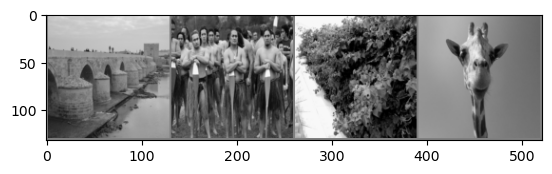

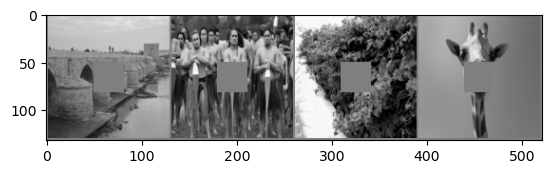

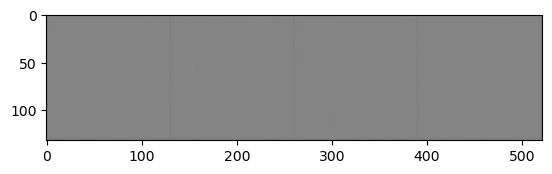

In [15]:
# Print some samples of dataset as a sanity check

# Get some random training images
dataiter = iter(trainloader)
example_images = next(dataiter)

print(example_images.shape)

# Show images
imshow(torchvision.utils.make_grid(example_images))

# Show masked images (center mask)
center_mask = generate_center_mask(example_images[0].shape)

masked_images = example_images * center_mask
imshow(torchvision.utils.make_grid(masked_images))

result = generator(masked_images)
imshow(torchvision.utils.make_grid(result))


### discriminator

#### tiny

In [16]:

class Discriminator(nn.Module):
    def __init__(self, in_channels):
        super(Discriminator, self).__init__()

        # Input: (1, 128, 128)
        self.conv1 = nn.Conv2d(in_channels, 64, kernel_size=4, stride=2, padding=1)   # (64, 64, 64)
        
        self.conv2 = nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1) # (128, 32, 32)
        self.bn2 = nn.BatchNorm2d(128)

        self.conv3 = nn.Conv2d(128, 1, kernel_size=8)  # (1, 1, 1) – global decision 
        #(only one needed since the other is inevitably given by the remaining)

    def forward(self, x):
        x = self.conv1(x)
        x = F.leaky_relu(x, 0.2)

        x = self.conv2(x)
        #x = self.bn2(x)
        x = F.leaky_relu(x, 0.2)

        x = self.conv3(x)
        
        return x.view(-1)  # flatten to [batch_size] 
                            # sigmoid already included in BCEWithLogitsLoss()


#### medium

In [ ]:

class DiscriminatorM(nn.Module):
    def __init__(self, in_channels):
        super(Discriminator, self).__init__()

        # Input: (1, 128, 128)
        self.conv1 = nn.Conv2d(in_channels, 64, kernel_size=4, stride=2, padding=1)   # (64, 64, 64)
        self.conv2 = nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1) # (128, 32, 32)
        self.bn2 = nn.BatchNorm2d(128)

        self.conv3 = nn.Conv2d(128, 256, kernel_size=4, stride=2, padding=1) # (256, 16, 16)
        self.bn3 = nn.BatchNorm2d(256)

        self.conv4 = nn.Conv2d(256, 512, kernel_size=4, stride=2, padding=1) # (512, 8, 8)
        self.bn4 = nn.BatchNorm2d(512)

        self.conv5 = nn.Conv2d(512, 1, kernel_size=8)  # (1, 1, 1) – global decision 
        #(only one needed since the other is inevitably given by the remaining)

    def forward(self, x):
        x = F.leaky_relu(self.conv1(x), 0.2)
        x = self.conv2(x)
        #x = self.bn2(x)
        x = F.leaky_relu(x, 0.2)
        x = self.conv3(x)
        #x = self.bn3(x)
        x = F.leaky_relu(x, 0.2)
        x = self.conv4(x)
        #x = self.bn4(x)
        x = F.leaky_relu(x, 0.2)
        x = self.conv5(x)
        return x.view(-1)  # flatten to [batch_size] 
                            # sigmoid already included in BCEWithLogitsLoss()


## path directory

### google colab

In [ ]:
base_dir = '/content/drive/MyDrive/Image Inpainting/my_models'

### local

In [ ]:
base_dir = './models1'

## save model

### model initialization

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")#'cuda:0'
print(device)
print(f"cuda available :{torch.cuda.is_available()}")
print(f"device name: {torch.cuda.get_device_name(0)}") if torch.cuda.is_available() else print("cuda not available")

generator = UNet(in_channels=channels, out_channels=channels).to(device)

loading = False 
if loading:
  generator.load_state_dict(torch.load(G_string))

num_epochs = 50

In [ ]:
import os 
from datetime import datetime

now = datetime.now().strftime("%Y%m%d_%H%M")
save_dir = os.path.join(base_dir, now)

os.makedirs(save_dir, exist_ok=True)

model_name = "UNet_Part"
G_string = f'{save_dir}/{model_name}_G.pth'

torch.save(generator.state_dict(), G_string)
print(f"Model {model_name} saved to: {G_string}")

In [ ]:
discriminator = Discriminator(in_channels=channels).to(device)
if loading:
  discriminator.load_state_dict(torch.load(D_string))

In [ ]:
D_string = f'{save_dir}/{model_name}_D.pth'
torch.save(discriminator.state_dict(), D_string)
print(f"Model {model_name} saved to: {D_string}")

## TRAINING

In [ ]:
adversarial_loss = nn.BCEWithLogitsLoss()
reconstruction_loss = nn.L1Loss()  # or nn.MSELoss()


### Generator only training (AutoEncoder)

In [ ]:

def run_generator_stepAE(batch_data, mask, train=False, mask_weight = 0.8):

    # Reconstruction loss
    generated = generator(batch_data * mask)
    rec_loss = reconstruction_loss(generated,batch_data)
    # Mask loss
    masked = (1 - mask) # mask shaped tensor returns 1 if masked pixel
    abs_err = torch.abs(generated - batch_data)
    mask_loss = torch.sum(abs_err * masked) / torch.sum(masked) # scalar

    
    # Total G loss
    loss = (1-mask_weight)*rec_loss + mask_weight*mask_loss
    
    if train:
        optimizer_G.zero_grad()
        loss.backward()
        optimizer_G.step()
    
    return loss.item()


In [ ]:
print(next(generator.parameters()).device)
print(next(discriminator.parameters()).device)
num_epochs = 30
print(num_epochs)
generator

In [ ]:
# Optimizers
optimizer_G = optim.Adam(generator.parameters(), lr=1e-4)
tr_losses_G = np.zeros(num_epochs)
val_losses_G = np.zeros(num_epochs)

best_val_loss_G = float('inf')

for epoch_nr in range(num_epochs):
    print(f"\nEpoch {epoch_nr}:")

    generator.train()
    running_loss_G = 0.0

    for batch_data in trainloader:
        batch_data = batch_data.to(device)  # real images
        mask = generate_center_mask(batch_data.shape[1:]).to(device)

        running_loss_G += run_generator_stepAE(batch_data, mask, train=True)

    tr_losses_G[epoch_nr] = running_loss_G / len(trainloader)


    print(f">> TRAIN Epoch {epoch_nr} | Generator Loss: {tr_losses_G[epoch_nr]:.4f}")

    # === Validation ===
    generator.eval()

    val_loss_G = 0.0

    with torch.no_grad():
        for val_data in valloader:
            val_data = val_data.to(device)
            mask = generate_center_mask(val_data.shape[1:]).to(device)


            val_loss_G  += run_generator_stepAE(val_data, mask, train=False)

    val_losses_G[epoch_nr] = val_loss_G  / len(valloader)

    print(f">> VALIDATION Epoch {epoch_nr} | Generator Loss: {val_losses_G[epoch_nr]:.4f}")

    if val_losses_G[epoch_nr] < best_val_loss_G:
        print(f"Validation loss improved, saving generator model for epoch {epoch_nr}")
        best_val_loss_G = val_losses_G[epoch_nr]
        torch.save(generator.state_dict(), G_string)  # Save the generator model


print("Training finished.")


### GAN training (generator + discriminator)

https://stackoverflow.com/questions/57652576/l1-vs-l2-or-mse-vs-mae-and-euclidean-norm-formulas-are-different-why-use-inte#:~:text=L1%20is%20the%20sum%20of,mean%20of%20the%20squared%20errors.

In [ ]:
# Optimizers
optimizer_G = optim.Adam(generator.parameters(), lr=1e-4)
tr_losses_G = np.zeros(num_epochs)
val_losses_G = np.zeros(num_epochs)


optimizer_D = optim.Adam(discriminator.parameters(), lr=1e-4)
tr_losses_D = np.zeros(num_epochs)
val_losses_D = np.zeros(num_epochs)

def run_generator_step(batch_data, mask, train=False, rec_weight = 0.9, mask_weight = 0.8):

    # Reconstruction loss
    generated = generator(batch_data * mask)
    rec_loss = reconstruction_loss(generated,batch_data)
    # Mask loss
    masked = (1 - mask) # mask shaped tensor returns 1 if masked pixel
    abs_err = torch.abs(generated - batch_data)
    mask_loss = torch.sum(abs_err * masked) / torch.sum(masked) # scalar

    # Adversarial loss
    pred = discriminator(generated)
    real = torch.ones_like(pred)
    adv_loss = adversarial_loss(pred, real)

    # Total G loss
    loss = (1-rec_weight) * adv_loss + rec_weight * ((1-mask_weight)*rec_loss + mask_weight*mask_loss)

    if train:
        optimizer_G.zero_grad()
        loss.backward()
        optimizer_G.step()

    return loss.item()

def run_discriminator_step(batch_data, mask, train=False):


    # Real loss
    pred = discriminator(batch_data)
    real = torch.ones_like(pred)
    real_loss = adversarial_loss(pred, real)

    # Fake loss
    generated = generator(batch_data * mask)
    pred = discriminator(generated.detach()) # (detach so G weights not updated)
    fake = torch.zeros_like(pred)
    fake_loss = adversarial_loss(pred, fake)

    # Total loss
    loss = 0.5 * (real_loss + fake_loss)

    if train:
        optimizer_D.zero_grad()
        loss.backward()
        optimizer_D.step()

    return loss.item()


Epoch 0:
>> TRAIN Epoch 0 | Generator Loss: 1.2561, Discriminator Loss: 0.7032
>> VALIDATION Epoch 0 | Generator Loss: 1.1979, Discriminator Loss: 0.7887
Training finished.


#### training

In [ ]:
print(next(generator.parameters()).device)
print(next(discriminator.parameters()).device)
num_epochs = 30
print(num_epochs)

In [ ]:
generator

In [ ]:
best_val_loss_G = float('inf')
D_steps = 3

for epoch_nr in range(num_epochs):
    print(f"\nEpoch {epoch_nr}:")

    generator.train()
    discriminator.train()
    running_loss_G = 0.0
    running_loss_D = 0.0

    for batch_data in trainloader:
        batch_data = batch_data.to(device)  # real images
        mask = generate_center_mask(batch_data.shape[1:]).to(device)       

        for _ in range (D_steps):
            running_loss_D += run_discriminator_step(batch_data, mask, train=True)
        
        running_loss_G += run_generator_step(batch_data, mask, train=True)

    tr_losses_G[epoch_nr] = running_loss_G / len(trainloader)
    tr_losses_D[epoch_nr] = running_loss_D / (D_steps * len(trainloader))

    print(f">> TRAIN Epoch {epoch_nr} | Generator Loss: {tr_losses_G[epoch_nr]:.4f}, Discriminator Loss: {tr_losses_D[epoch_nr]:.4f}")

    # === Validation ===
    generator.eval()
    discriminator.eval()
    val_loss_G = 0.0
    val_loss_D = 0.0
    with torch.no_grad():
        for val_data in valloader:
            val_data = val_data.to(device)
            mask = generate_center_mask(val_data.shape[1:]).to(device)       
            
            val_loss_D  += run_discriminator_step(val_data, mask, train=False)
            val_loss_G  += run_generator_step(val_data, mask, train=False)

    val_losses_G[epoch_nr] = val_loss_G  / len(valloader)
    val_losses_D[epoch_nr] = val_loss_D  / len(valloader)
    print(f">> VALIDATION Epoch {epoch_nr} | Generator Loss: {val_losses_G[epoch_nr]:.4f}, Discriminator Loss: {val_losses_D[epoch_nr]:.4f}")

    if val_losses_G[epoch_nr] < best_val_loss_G:
        print(f"Validation loss improved, saving generator model for epoch {epoch_nr}")
        best_val_loss_G = val_losses_G[epoch_nr]
        torch.save(generator.state_dict(), G_string)  # Save the generator model
        torch.save(discriminator.state_dict(), D_string)

print("Training finished.")


In [ ]:
print(f"Number of training samples: {len(trainloader.dataset)}")
print(f"Number of validation samples: {len(valloader.dataset)}")

In [ ]:
save_path = f'{save_dir}/AE_epoch30.txt'
text_content = ""
# Write to the file
with open(save_path, 'w') as f:
    f.write(text_content)

## load model

In [ ]:
# load model
generator.load_state_dict(torch.load(G_string))


C:\Users\Kamil\AppData\Local\Temp\ipykernel_13468\3255354345.py:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  generator.load_state_dict(torch.load(G_string))
C:\Users\Kam

<All keys matched successfully>

In [ ]:
discriminator.load_state_dict(torch.load(D_string))

## visualization

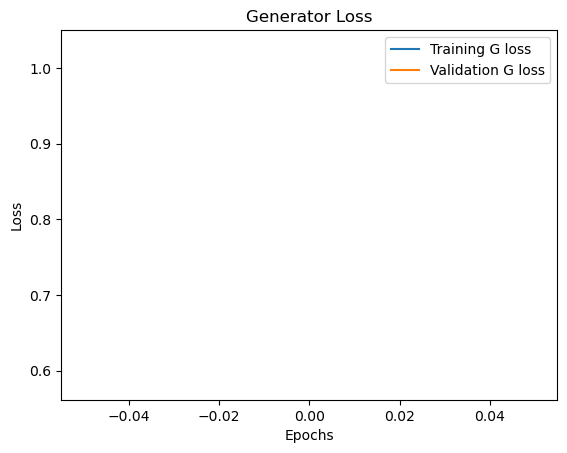

In [ ]:
plt.figure()
plt.plot(tr_losses_G, label='Training G loss')
plt.plot(val_losses_G, label='Validation G loss')
plt.title('Generator Loss')
plt.ylabel('Loss')
plt.xlabel('Epochs')
plt.legend()
# Save the figure
plt.savefig(f'{save_dir}/Generator_Loss_Plot.png', dpi=600)
plt.show()

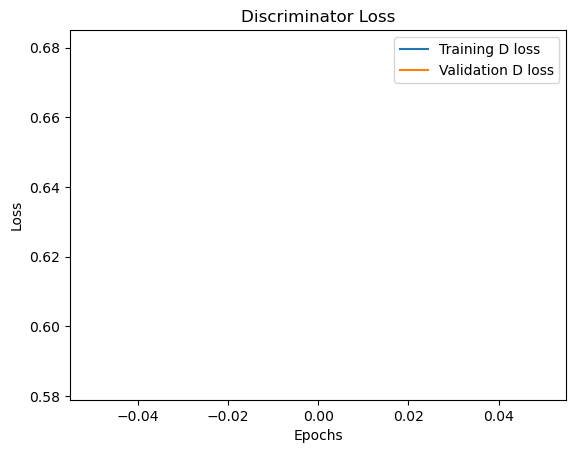

In [ ]:
plt.figure()
plt.plot(tr_losses_D, label='Training D loss')
plt.plot(val_losses_D, label='Validation D loss')
plt.title('Discriminator Loss')
plt.ylabel('Loss')
plt.xlabel('Epochs')
plt.legend()
plt.savefig(f'{save_dir}/Discriminator_Loss_Plot.png', dpi=600)

plt.show()

## sanity check

torch.Size([4, 1, 128, 128])


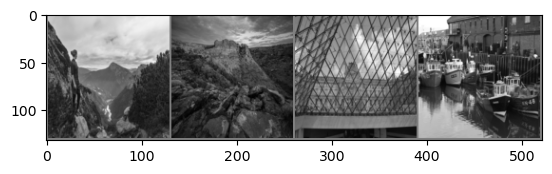

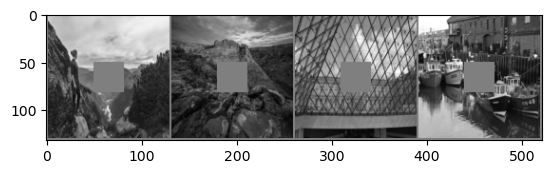

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.117750406..0.5].


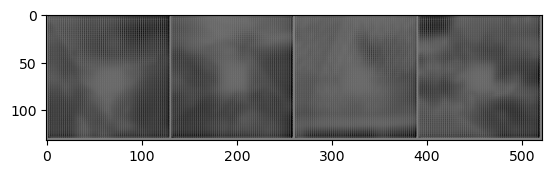

In [ ]:
# Print some samples of dataset as a sanity check
device = torch.device("cpu")
print(device)
generator = UNet(in_channels=channels, out_channels=channels).to(device)
# load model
generator.load_state_dict(torch.load(
    G_string,
    map_location=torch.device('cpu'),
))


# Get some random training images
dataiter = iter(valloader)
example_images = next(dataiter)

print(example_images.shape)

# Show images
imshow(torchvision.utils.make_grid(example_images),f'{save_dir}/Original.png')

# Show masked images (center mask)
center_mask = generate_center_mask(example_images[0].shape)

masked_images = example_images * center_mask
imshow(torchvision.utils.make_grid(masked_images),f'{save_dir}/Masked.png')

result = generator(masked_images)
imshow(torchvision.utils.make_grid(result),f'{save_dir}/Output.png')


# sources

[Partial Convolutions](https://arxiv.org/pdf/1804.07723)

[U-Net](https://arxiv.org/pdf/1505.04597)

[Inpainting](https://www.youtube.com/watch?v=kbwfYMlVCps)